# Feature Engineering

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw"
PROC_DATA_PATH = PROJECT_ROOT / "data" / "processed"
RESULTS_PATH = PROJECT_ROOT / "results"

In [2]:
energy_path = PROC_DATA_PATH / "energy_nyc.parquet"
energy = pd.read_csv(energy_path)
energy.head()

,time,respondent,Day-ahead demand forecast,Demand,Net generation,Total interchange
0,2022-01-01 00:00:00,NY,17215.0,18111.0,14636.0,-3475.0
1,2022-01-01 01:00:00,NY,16443.0,17580.0,14174.0,-3406.0
2,2022-01-01 02:00:00,NY,15713.0,17002.0,13807.0,-3195.0
3,2022-01-01 03:00:00,NY,15200.0,16415.0,13274.0,-3141.0
4,2022-01-01 04:00:00,NY,14903.0,15767.0,12485.0,-3282.0


In [3]:
energy["time"] = pd.to_datetime(energy["time"])
energy["hour"] = energy["time"].dt.hour
energy["day"] = energy["time"].dt.day_of_week
energy["month"] = energy["time"].dt.month
energy["is_weekend"] = energy["time"].dt.dayofweek > 4
energy["is_weekend"] = energy["is_weekend"].astype(int)
energy["lag_1"] = energy["Demand"].shift(1)
energy["lag_24"] = energy["Demand"].shift(24)
energy["lag_48"] = energy["Demand"].shift(48)
energy["lag_168"] = energy["Demand"].shift(168)
energy["rolling_mean_24"] = energy["Demand"].rolling(window=24).mean()
energy["rolling_std_24"] = energy["Demand"].rolling(window=24).std()
energy = energy.set_index("time")
energy.head()

,respondent,Day-ahead demand forecast,Demand,Net generation,Total interchange,hour,day,month,is_weekend,lag_1,lag_24,lag_48,lag_168,rolling_mean_24,rolling_std_24
time,,,,,,,,,,,,,,,
2022-01-01 00:00:00,NY,17215.0,18111.0,14636.0,-3475.0,0,5,1,1,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-01 01:00:00,NY,16443.0,17580.0,14174.0,-3406.0,1,5,1,1,18111.0,NaN,NaN,NaN,NaN,NaN
2022-01-01 02:00:00,NY,15713.0,17002.0,13807.0,-3195.0,2,5,1,1,17580.0,NaN,NaN,NaN,NaN,NaN
2022-01-01 03:00:00,NY,15200.0,16415.0,13274.0,-3141.0,3,5,1,1,17002.0,NaN,NaN,NaN,NaN,NaN
2022-01-01 04:00:00,NY,14903.0,15767.0,12485.0,-3282.0,4,5,1,1,16415.0,NaN,NaN,NaN,NaN,NaN


## Making Baselines

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.compose import ColumnTransformer
import lightgbm as lgb
from lightgbm import LGBMRegressor
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [5]:
energy_data = energy.dropna()
energy_data.head()

,respondent,Day-ahead demand forecast,Demand,Net generation,Total interchange,hour,day,month,is_weekend,lag_1,lag_24,lag_48,lag_168,rolling_mean_24,rolling_std_24
time,,,,,,,,,,,,,,,
2022-01-08 00:00:00,NY,20236.0,21323.0,18766.0,-2557.0,0,5,1,1,21468.0,20781.0,20281.0,18111.0,18693.666667,1944.542344
2022-01-08 01:00:00,NY,19729.0,20897.0,18399.0,-2498.0,1,5,1,1,21323.0,20323.0,19770.0,17580.0,18717.583333,1968.831653
2022-01-08 02:00:00,NY,19191.0,20353.0,17670.0,-2683.0,2,5,1,1,20897.0,19739.0,19074.0,17002.0,18743.166667,1986.590299
2022-01-08 03:00:00,NY,18550.0,19631.0,16668.0,-2963.0,3,5,1,1,20353.0,18956.0,18247.0,16415.0,18771.291667,1994.496874
2022-01-08 04:00:00,NY,17756.0,18730.0,15119.0,-3611.0,4,5,1,1,19631.0,17891.0,17185.0,15767.0,18806.250000,1985.730295


In [6]:
n = len(energy_data)
train_end = int(n*0.80)
val_end = int(n*0.90)
train_data = energy_data.iloc[:train_end]
val_data = energy_data.iloc[train_end: val_end]
test_data = energy_data.iloc[val_end:]

constant_features = ["hour", "day", "month", "is_weekend"]
scale_features_lag_1 = ["lag_1"]
targets = ["Demand"]

master_features_to_scale = ["lag_1", "lag_24", "lag_48", "lag_168", "rolling_mean_24", "rolling_std_24"]

In [7]:
def get_preprocessor(current_features):
	features_to_scale = [f for f in current_features if f in master_features_to_scale]
	return ColumnTransformer(
		transformers=[("scaler", StandardScaler(), features_to_scale)],
		remainder="passthrough",
	)

In [8]:
n = len(energy_data)
train_end = int(n*0.80)
val_end = int(n*0.90)
train_data = energy_data.iloc[:train_end]
val_data = energy_data.iloc[train_end: val_end]
test_data = energy_data.iloc[val_end:]

features = ["hour", "day", "month", "is_weekend", "lag_1", "lag_24", "lag_48", "lag_168", "rolling_mean_24", "rolling_std_24"]
master_features_to_scale = ["lag_1", "lag_24", "lag_48", "lag_168", "rolling_mean_24", "rolling_std_24"]
targets = ["Demand"]

preprocessor = ColumnTransformer(
	transformers=[("scaler", StandardScaler(), features_to_scale)],
	remainder="passthrough"
)

X_train = preprocessor.fit_transform(train_data[features])
X_val = preprocessor.fit_transform(val_data[features])
X_test = preprocessor.fit_transform(test_data[features])
y_train = train_data[targets]
y_val = val_data[targets]
y_test = test_data[targets]

NameError: name 'features_to_scale' is not defined

In [ ]:
all_metrics = []
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
y_pred = ridge.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

all_metrics.append({
	"name": "Ridge",
	"model": ridge,
	"mae": mae,
	"rmse": rmse,
})

In [ ]:
train_dataset = lgb.Dataset(X_train, label=y_train)
val_dataset = lgb.Dataset(X_val, label = y_val, reference=train_dataset)
params = {
	"objective": "regression",
	"metric": "rmse",
	"learning_rate": 0.05,
	"num_leaves": 31,
	"seed": 42,
	"verbose": -1
}
lgb_model = lgb.train(
	params=params,
	train_set=train_dataset,
	num_boost_round=1000,
	valid_sets=[train_dataset, val_dataset],
	valid_names=["train", "valid"],
	callbacks=[lgb.early_stopping(stopping_rounds=50)]
)
y_pred = lgb_model.predict(X_test, num_iteration=lgb_model.best_iteration)
mae = mean_absolute_error(y_pred, y_test)
rmse = np.sqrt(mean_squared_error(y_pred, y_test))

all_metrics.append({
	"name": "LightGBM",
	"model": lgb_model,
	"mae": mae,
	"rmse": rmse
})

Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[255]	train's rmse: 242.545	valid's rmse: 913.151


In [ ]:
metrics_df = pd.DataFrame(all_metrics)
metrics_df

,name,model,mae,rmse
0,Ridge,Ridge(),463.955426,591.099129
1,LightGBM,<lightgbm.basic.Booster object at 0x000001C9F3...,352.214961,458.045132


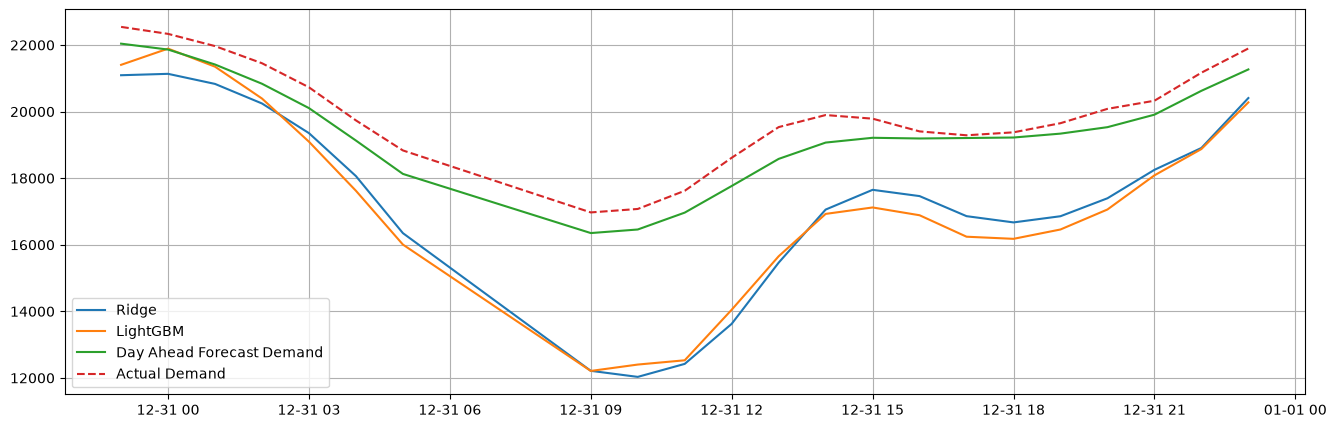

In [ ]:
time_span = 24
test_data_span = test_data[test_data.index >= (test_data.index.max() - pd.Timedelta(hours=time_span))]
X_test = preprocessor.fit_transform(test_data_span[features])
y_test = test_data_span[targets]
num_models = len(metrics_df["model"])
fig, ax = plt.subplots(figsize=(16, 5))
for i in range(num_models):
	ax.plot(test_data_span.index, metrics_df["model"].iloc[i].predict(X_test), label=metrics_df["name"].iloc[i])
ax.plot(test_data_span.index, test_data_span["Day-ahead demand forecast"], label="Day Ahead Forecast Demand")
ax.plot(test_data_span.index, y_test, label="Actual Demand", linestyle="--")
ax.grid(True)
ax.legend()



## Making LSTM Models

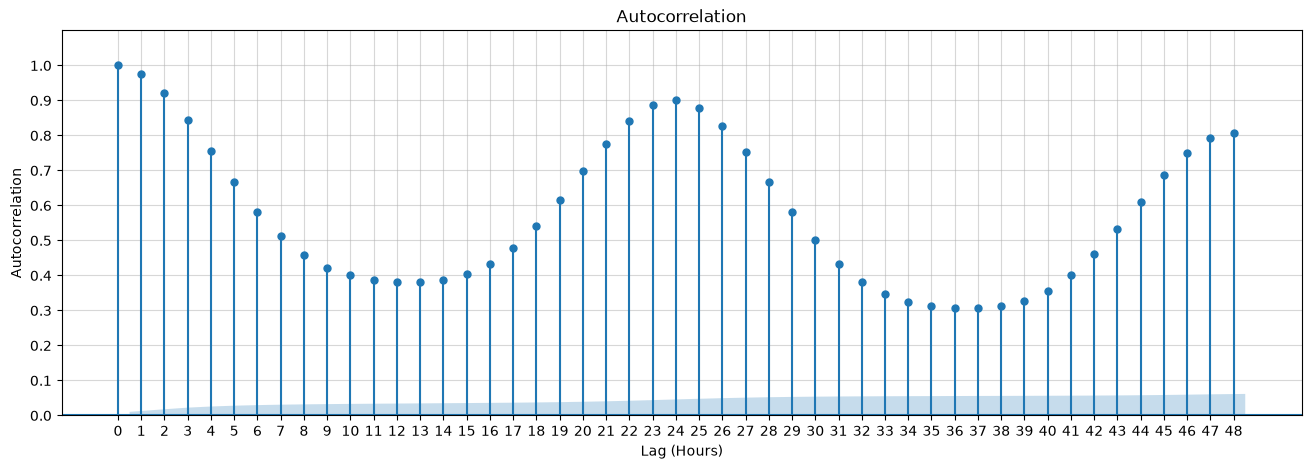

In [31]:
from statsmodels.graphics.tsaplots import plot_acf
hours_window = 48
fig, ax = plt.subplots(figsize=(16, 5))
plot_acf(energy["Demand"], lags=hours_window, ax=ax)
plt.xlabel("Lag (Hours)")
plt.ylabel("Autocorrelation")
plt.grid(True, alpha=0.5)
plt.ylim(bottom=0, top=1.1)
plt.xticks(ticks=range(0,hours_window + 1))
plt.yticks(ticks=np.arange(0.0, 1.1, 0.1))
plt.show()

In [40]:
energy["hour_sin"] = np.sin(2 * np.pi * energy["hour"] / 24.0)
energy["hour_cos"] = np.cos(2 * np.pi * energy["hour"] / 24.0)
energy["day_sin"] = np.sin(2 * np.pi * energy["day"] / 7.0)
energy["day_cos"] = np.cos(2 * np.pi * energy["day"] / 7.0)
energy["month_sin"] = np.sin(2 * np.pi * energy["month"] / 12.0)
energy["month_cos"] = np.cos( 2 * np.pi * energy["month"] / 12.0)
scaler = StandardScaler()
energy["demand_scaled"] = scaler.fit_transform(energy[["Demand"]])
energy_lstm = energy.drop(columns=["lag_1", "lag_24", "lag_48", "lag_168", "rolling_mean_24", "rolling_std_24"])
energy_lstm.head()

,respondent,Day-ahead demand forecast,Demand,Net generation,Total interchange,hour,day,month,is_weekend,hour_sin,hour_cos,day_sin,day_cos,month_sin,month_cos,demand_scaled
time,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,NY,17215.0,18111.0,14636.0,-3475.0,0,5,1,1,0.000000,1.000000,-0.974928,-0.222521,0.5,0.866025,0.304988
2022-01-01 01:00:00,NY,16443.0,17580.0,14174.0,-3406.0,1,5,1,1,0.258819,0.965926,-0.974928,-0.222521,0.5,0.866025,0.132403
2022-01-01 02:00:00,NY,15713.0,17002.0,13807.0,-3195.0,2,5,1,1,0.500000,0.866025,-0.974928,-0.222521,0.5,0.866025,-0.055459
2022-01-01 03:00:00,NY,15200.0,16415.0,13274.0,-3141.0,3,5,1,1,0.707107,0.707107,-0.974928,-0.222521,0.5,0.866025,-0.246245
2022-01-01 04:00:00,NY,14903.0,15767.0,12485.0,-3282.0,4,5,1,1,0.866025,0.500000,-0.974928,-0.222521,0.5,0.866025,-0.456858


In [41]:
master_len = len(energy_lstm)
train_end = int(n*0.80)
val_end = int(n*0.90)
train_data = energy_lstm.iloc[:train_end]
val_data = energy_lstm.iloc[train_end: val_end]
test_data = energy_lstm.iloc[val_end:]

In [42]:
feature_list = ["demand_scaled", "is_weekend", "hour_sin", "hour_cos", "day_sin", "day_cos", "month_sin", "month_cos"]
train_np = train_data[feature_list].values
val_np = val_data[feature_list].values
test_np = test_data[feature_list].values

In [44]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

In [51]:
class TimeSeriesDataset(Dataset):
	def __init__(self, data, lag=24):
		self.data = torch.tensor(data, dtype=torch.float32)
		self.lag = lag

	def __len__(self):
		return len(self.data) - self.lag

	def __getitem__(self, idx):
		X = self.data[idx: idx + self.lag]
		y = self.data[idx + self.lag, 0:1]
		return X, y

lag=24
BATCH_SIZE = 32

train_dataset = TimeSeriesDataset(train_np, lag=lag)
val_dataset = TimeSeriesDataset(val_np, lag=lag)
test_dataset = TimeSeriesDataset(test_np, lag=lag)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)


In [52]:
class EnergyLSTM(nn.Module):
	def __init__(self, input_size=8, hidden_size=64, num_layers=2):
		super(EnergyLSTM, self).__init__()
		self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)
		self.fc = nn.Linear(hidden_size, 1)

	def forward(self, x):
		lstm_out, _ = self.lstm(x)
		last_time_step = lstm_out[:, -1, :]
		out = self.fc(last_time_step)
		return out

model = EnergyLSTM(input_size=8, hidden_size=64, num_layers=2)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [53]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
epochs = 50
patience = 5
best_val_loss = float("inf")
patience_counter = 0

model = model.to(device)
print(f"Training on device: {device}")

for epoch in range(1, epochs + 1):
	model.train()
	train_loss = 0.0
	for X_batch, y_batch in train_loader:
		X_batch, y_batch = X_batch.to(device), y_batch.to(device)
		optimizer.zero_grad()
		predictions = model(X_batch)
		loss = criterion(predictions, y_batch)
		loss.backward()
		optimizer.step()
		train_loss += loss.item() * X_batch.size(0)
	epoch_train_loss = train_loss / len(train_loader.dataset)
	
	
	model.eval()
	val_loss = 0.0
	with torch.no_grad():
		for X_batch, y_batch in val_loader:
			X_batch, y_batch = X_batch.to(device), y_batch.to(device)
			predictions = model(X_batch)
			loss = criterion(predictions, y_batch)
			val_loss += loss.item() * X_batch.size(0)
	epoch_val_loss = val_loss / len(val_loader.dataset)
	print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss (MSE): {epoch_train_loss:.4f} | Val Loss(MSE): {epoch_val_loss:.4f}")

	if epoch_val_loss < best_val_loss:
		best_val_loss = epoch_val_loss
		torch.save(model.state_dict(), "best_energy_lstm.pth")
		print(f"	---> Validation loss decreased! Model saved.")
		patience_counter = 0
	else:
		patience_counter += 1
		print(f"	---> Validation loss did not improve. Counter: {patience_counter}/{patience}")
	if patience_counter >= patience:
		print("\nEarly stopping triggered! Training stopped tp prevent overfitting.")
		break
print(f"\nTraining completed. Best validation loss achieved: {best_val_loss:.4f}")

Training on device: cpu
Epoch 01/50 | Train Loss (MSE): 0.0891 | Val Loss(MSE): 0.0476
	---> Validation loss decreased! Model saved.
Epoch 02/50 | Train Loss (MSE): 0.0158 | Val Loss(MSE): 0.0103
	---> Validation loss decreased! Model saved.
Epoch 03/50 | Train Loss (MSE): 0.0122 | Val Loss(MSE): 0.0071
	---> Validation loss decreased! Model saved.
Epoch 04/50 | Train Loss (MSE): 0.0115 | Val Loss(MSE): 0.0075
	---> Validation loss did not improve. Counter: 1/5
Epoch 05/50 | Train Loss (MSE): 0.0112 | Val Loss(MSE): 0.0083
	---> Validation loss did not improve. Counter: 2/5
Epoch 06/50 | Train Loss (MSE): 0.0110 | Val Loss(MSE): 0.0092
	---> Validation loss did not improve. Counter: 3/5
Epoch 07/50 | Train Loss (MSE): 0.0107 | Val Loss(MSE): 0.0108
	---> Validation loss did not improve. Counter: 4/5
Epoch 08/50 | Train Loss (MSE): 0.0104 | Val Loss(MSE): 0.0090
	---> Validation loss did not improve. Counter: 5/5

Early stopping triggered! Training stopped tp prevent overfitting.

Train

In [56]:
def inverse_tranform_target(values, scaler, n_features=8):
	values = np.asarray(values).reshape(-1)
	dummy = np.zeros((len(values), n_features))
	dummy[:, 0] = values
	return scaler.inverse_transform(dummy)[:, 0]

In [57]:
model.eval()
y_true = []
y_pred = []
with torch.no_grad():
	for X_batch, y_batch in test_loader:
		X_batch = X_batch.to(device)
		predictions = model(X_batch)
		y_true.extend(y_batch.cpu().numpy().ravel())
		y_pred.extend(predictions.cpu().numpy().ravel())

y_true = inverse_tranform_target(y_true, scaler)
y_pred = inverse_tranform_target(y_pred, scaler)

mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

print(f"Test MAE	: {mae:.4f}")
print(f"Test RMSE	: {rmse:.4f}")

Test MAE	: 163.4312
Test RMSE	: 212.0893


In [59]:
y_pred

array([20973.54227177, 22131.2617568 , 23097.69254268, ...,
       20663.14110847, 20578.95261715, 22069.17184127], shape=(3756,))

In [ ]:
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot()